# Phase 6 — Forecast models

**Goal.** Find the variance forecast that makes the strategy work best, not just the one with the smallest error. Eight models, simplest first, are each scored twice. Scorecard A asks how accurate the forecast is (QLIKE, Model Confidence Set). Scorecard B asks how well the strategy does with it (the Phase 5 engine at the primary specification). A rule fixed in advance then picks one model for the combined portfolio and one for the SPY reference, and freezes them. **Development sample only (to 2018).** The 2019+ holdout is never loaded.

### Key findings

1. **The engine reproduces the published single-factor results.** Market: α of 4.69% a year against Moreira and Muir's 4.86%. Momentum: Sharpe 0.49 to 0.89 against Barroso and Santa-Clara's 0.53 to 0.97, on French's UMD factor, not their decile spread.
2. **The hints, re-run on the series being forecast:**
   - Long memory and VIX: both pass on the primary mix $p_t$ and on the market.
   - Bad days raising risk (Test 3): passes on neither, so M6 and M7 build on the plain HAR (M4).
   - Curvature: only on the market.
3. **Accuracy (Scorecard A): the HAR family wins, rolling RV loses.**
   - On both books, HAR-X (M6) has the lowest QLIKE, with the downside HAR and HAR close behind.
   - Rolling RV (M0), the papers' baseline, is the least accurate model on both and the only one dropped from the primary book's Model Confidence Set (MCS p 0.001). The other seven are statistically tied there.
   - On the market, EWMA and boosting are dropped as well.
4. **Strategy value (Scorecard B): every forecast beats buy-and-hold on the primary book, and they barely differ.**
   - The eight timed Sharpe ratios run from 1.51 to 1.57, against buy-and-hold's 1.21. Every gain reads "edge" on the primary test, and every real forecast beats all 1,000 shuffled ones.
   - These are upper bounds: untradeable BAB, no costs, development sample.
   - On the market, the gains are small (0.01–0.04) and every reading is "inconclusive".
5. **A perfect forecast would add far more than any real one.** The oracle (next month's actual variance) beats rolling RV by 0.71 Sharpe on the primary book and 0.61 on the market. The best and worst of the eight models differ by only 0.06 and 0.03.
6. **Accuracy barely predicts strategy value on the primary book (Q4).**
   - The rank correlation between the two scorecards is +0.10 on the primary book, against +0.62 on the market.
   - The GARCH models sit mid-table on QLIKE but top on Sharpe. Their smoother forecasts let the real-time $c_t$ hold a larger average size (1.00 against rolling RV's 0.67), and the 1.5 cap then binds more often.
   - Across the eight, the Sharpe ranking follows the average size (+0.76), not accuracy.
   - Forecast accuracy is not the bottleneck.
7. **Frozen choices.**
   - **Combined portfolio: M3, GJR-GARCH.** It has the best Sharpe ratio, and no simpler model inside the MCS is within one standard error of it. This is a knife-edge: EWMA misses by 0.002 Sharpe.
   - **SPY reference: M2, GARCH(1,1),** the simplest model inside the MCS within one standard error of the best.
8. **A bug was found after the first run and fixed in a dated entry (PREREGISTRATION Entry 5).**
   - In the first run, the GARCH optimizer sometimes reported success at absurd parameters, and some GJR forecasts reached 10¹⁰ times the realized variance.
   - That run chose rolling RV for the combined portfolio, but only because the broken model distorted the Model Confidence Set. That choice is void.
   - The re-run, with two safeguards whose estimates match the `arch` package, decides. Section 11 shows both runs.

### How to read this notebook

Section 1 states the rules (PREREGISTRATION Entry 4). Sections 2 and 3 are the checks and hints that come before any score. Sections 4–9 are the forecasts, the two scorecards and the selection. Sections 10 and 11 are information only. Numbers quoted in the text are from the build of 2026-10-18; the tables and figures are recomputed each time the notebook runs. The forecasts are read from the cache that `python -m src.models.build` fills: about an hour on 10 cores the first time (boosting is most of it), seconds afterwards.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from src import engine as e
from src import models as md
from src import variance as v
from src.config import EVENTS
from src.data.load import load_dev
from src.engine import evaluation as ev, forecast as fc, weights as wt
from src.models import build, inputs, scorecard as sc

pd.set_option("display.float_format", "{:,.4f}".format, "display.max_columns", 30, "display.width", 200,
              "display.max_colwidth", None)

BOOK_NAMES = {"paper": "Primary (market + momentum + BAB)", "spy": "SPY reference (market factor)"}
BLUE, AMBER, PURPLE = "#2a78d6", "#eda100", "#4a3aa7"                  # Phase 2-5's first three hues
LIGHT, DARK = "#86b6ef", "#1c5cab"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

panel = load_dev()
specs = build.setup(panel)            # each book, its costs, the series Phase 2's hints run on, and its eight forecasters
print("forecast cache:", inputs.CACHE_ROOT.relative_to(ROOT))

forecast cache: data/processed/phase6_cache


## 1. The rules

All rules below were fixed in PREREGISTRATION Entry 4 before any real-data forecast was made or scored. Entry 4 also marks which details are the plan's and which were my choices.

### Match the horizon to the holding period

The strategy rebalances monthly, so every model forecasts the **total variance over the next 22 trading days**, Σ r² over days t+1 to t+22, made at the close of month t's last trading day from data up to that close. A one-day forecast stretched over a month would mix horizons and compound its errors. A weekly rule would use the next 5 days.

### The eight candidates, simplest first

| Model | Forecast of the next 22 days' variance | Expected to help if the hints show |
|---|---|---|
| **M0** Rolling RV | Σ r² over the last 22 days | always: the papers' baseline |
| **M1** EWMA | $22\,\hat\sigma^2_{t+1}$, with $\hat\sigma^2_{t+1} = 0.94\,\hat\sigma^2_t + 0.06\,r_t^2$ (the forecast is flat) | always: no fitting |
| **M2** GARCH(1,1) | $\sigma^2_t = \omega + a\varepsilon^2_{t-1} + b\sigma^2_{t-1}$; the $h$-step forecasts $\bar\sigma^2 + (a+b)^{h-1}(\sigma^2_{t+1} - \bar\sigma^2)$ summed over $h$ = 1 to 22, with $\bar\sigma^2 = \omega/(1-a-b)$ | short memory |
| **M3** GJR-GARCH | M2 plus $g\,\varepsilon^2_{t-1}\mathbf 1\{\varepsilon_{t-1}<0\}$; decays at $a + b + g/2$ | short memory plus asymmetry |
| **M4** HAR, log | regression of log(next 22 days' RV) on the logs of the 1-, 5- and 22-day mean r², fitted directly on the 22-day target, then $\exp(\widehat{\log RV} + \tfrac12 s^2)$ | long memory |
| **M5** Downside HAR | M4 plus the down-day share of each lag | long memory plus asymmetry |
| **M6** HAR-X | M4 or M5 plus log VIX variance, $(VIX/100)^2/12$, and the counts of scheduled FOMC, CPI and jobs days ahead | VIX adds information (Test 5) |
| **M7** Gradient boosting | M6's inputs, nonlinear: trees fitted with QLIKE's own loss (gamma deviance) | nonlinearity (Test 9); beats HAR out of sample |

All eight are built and scored. The hints in Section 3 only set expectations, with one exception: Test 3 decides whether M6 builds on M4 or on M5.

**Three details that are mine, not the plan's.**

- **The daily log term.** On a day with a near-zero return, log r² heads to minus infinity; on the primary mix it reaches 18 below its own mean. So in logs, the 1- and 5-day means are floored at 1/1000 of the 22-day mean. The floor binds on about 2.6% of days, as normal theory predicts.
- **The downside split.** In logs, splitting a lag into log downside and log upside variance fails, because one of the two is zero on every day. M5 adds each lag's down-day share instead: a unit of variance from down days can then predict more than a unit from up days.
- **M7's loss.** Gamma deviance is exactly twice QLIKE, and boosting with a log link forecasts the variance itself. So no back-transform is needed.

**Why the back-transform has a correction.** If log RV is normal with mean μ and variance s², then E[RV] = exp(μ + s²/2), not exp(μ). Skipping the term biases forecasts low. The strategy would absorb a constant scale error into $c_t$, but QLIKE punishes it, so the HAR models correct it.

### Estimation protocol

- **Expanding window, refit every month-end.** M7 is refit yearly (each December) because it is the costly model. GARCH costs 0.02 s a fit, so it is refit monthly. Every model makes its first forecast at the end of the mix's 120th month, so all eight are scored on the same months.
- **Embargo.** At each refit, the last 22 days of training targets are dropped. A row's target covers the 22 days after it, so those rows overlap the forecast period, and keeping them would leak the future into training.
- **Tuning.** M7's settings come from an inner walk-forward inside the training window only: each of its last three years is forecast by a model trained on rows whose targets end before that year starts.
- **One walk-forward per recipe.** The engine forecasts the variance of the mix held next month, applied to all its history (Entry 2). So each model runs its own walk-forward on each of the 78 recipes' mixes, every forecast made only from data up to its own month-end.

### Scorecard A: forecast accuracy

$$\mathrm{QLIKE}_t = \frac{RV_t}{\hat\sigma^2_t} - \ln\frac{RV_t}{\hat\sigma^2_t} - 1$$

Lower is better; zero is perfect.

- **Why QLIKE.** It ranks forecasts correctly even though realized variance is a noisy stand-in for true variance (Patton 2011). It depends only on the ratio RV/σ̂², so calm and wild months count on the same scale.
- **It punishes under-forecasting harder.** A ratio of 10 costs 6.70, and a ratio of 0.1 costs 1.40. Under-forecasting risk is the expensive mistake here: a big position in a storm.
- **Comparing all eight at once: the Model Confidence Set** (Hansen, Lunde and Nason 2011). It keeps every model that is not significantly worse than the best. Eight models mean 28 pairwise tests, and the MCS controls the error across all of them. Each round it asks whether the worst model's loss gap to the average is too large to be chance, drops it if so, and repeats. A model's MCS p-value says how strongly the data reject it; the 90% set keeps those with p ≥ 0.10.

### Scorecard B: strategy value

Each forecast is plugged into the Phase 5 engine with everything else at the primary specification: inverse-variance timing, inverse-volatility mix, monthly, cap 1.5, the track's costs, and real-time $c_t$. So only the forecast changes. Reported: Sharpe ratio, CER (12 × [mean − γ/2 × variance], with γ = 5), realized volatility (Entry 3: always beside a CER), the primary test's Sharpe gain over buy-and-hold, spanning α, size, turnover, the break-even cost and the placebo. **The oracle** (next month's actual variance, known in advance) is a reference row: the gap between it and M0 is all the room a forecast has to win.

### The selection rule, fixed in advance

**Pick the simplest model inside the MCS whose Sharpe ratio is within one standard error of the best.** When models tie statistically, the simpler one generalizes better: the one-standard-error rule of machine learning.

- **The standard error** is that of the gap Sharpe(best) − Sharpe(model), by the primary test's own method (Ledoit and Wolf, Newey-West 6 lags). The eight runs share their months and most of their returns, so the paired error is the one that says whether two models tie. The error of the best Sharpe ratio alone (about 0.15 over 68 years) would let every model through.
- **Fallback.** If no model of the MCS qualifies, the MCS condition is dropped.

Then the choice is frozen; its clean test is the holdout.

### Two frozen choices

One for the combined portfolio, chosen on the primary book. One for the SPY reference, chosen on the market factor, timed alone at SPY's costs. ETFs are never tuned on (SPY has 26 years before 2019), and the market factor is SPY's long-history stand-in.

In [2]:
display(pd.DataFrame({"value": md.MODEL_RULES}).astype(str))
display(pd.DataFrame({"value": sc.SCORE_RULES}).astype(str))

,value
horizon,22
min_months,120
embargo,22
refit,"{'M0': None, 'M1': None, 'M2': 'month', 'M3': 'month', 'M4': 'month', 'M5': 'month', 'M6': 'month', 'M7': 'year'}"
ewma_lambda,0.94
log_floor,0.001
x_min_months,60
m6_base,"M5 if Phase 2 Test 3 passes on the series forecast, else M4"


,value
rule,inv_var
max_size,1.5
mcs_level,0.1
mcs_block,12
mcs_reps,10000
seed,0
gamma,5


## 2. First, the published results (Entry 3)

**What and why.** Before scoring forecasts, the engine must reproduce what the papers report on single factors, with their own rules:

- **Barroso and Santa-Clara (2015), momentum.** Variance from the last 126 days, a fixed 12% annual target, no cap, 1927–2011. They report a Sharpe ratio of 0.53 raw and 0.97 managed.
- **Moreira and Muir (2017), market.** Last month's RV, with c set on the full sample (which uses the future), no cap, 1926–2015. They report α of 4.86% a year.

Our momentum is Kenneth French's UMD factor, a 2×3 sort. Barroso and Santa-Clara use the spread between the top and bottom momentum deciles, which is about twice as volatile. So our Sharpe ratios should be close to theirs, not equal, and our average size is larger.

In [3]:
rows = {}
# Barroso and Santa-Clara (2015): momentum, variance of the last 126 days, a fixed 12% target, no cap, 1927-2011
mom = e.Book.single(panel["mom"], panel["rf"], "mom")
r = e.run(mom, "inv_vol", forecaster=fc.rv_days(126), c=wt.target_c(0.12), max_size=None).loc[:"2011-12"]
rows["Momentum (Barroso and Santa-Clara)"] = {
    "months": f"{r.index[0]} to {r.index[-1]}", "published Sharpe: raw": 0.53, "published Sharpe: managed": 0.97,
    "Sharpe: raw": ev.sharpe(r["bench_excess"]), "Sharpe: managed": ev.sharpe(r["excess"]),
    "volatility: raw": r["bench_excess"].std() * np.sqrt(12), "volatility: managed": r["excess"].std() * np.sqrt(12),
    "mean size": r["size"].mean(), "alpha": ev.spanning(r["excess"], r["bench_excess"])["alpha"]}

# Moreira and Muir (2017): market, last month's RV, c on the full sample (it uses the future), no cap, 1926-2015
mkt = e.Book.single(panel["mkt"], panel["rf"], "mkt")
mon = e.prepare(mkt, fc.last_rv)[0].loc[:"2015-12"]
nxt = mon["ret"].shift(-1)
c_full = nxt.std() / (nxt * wt.signal(mon["forecast"], 1.0)).std()
r = e.run(mkt, "inv_var", c=c_full, max_size=None).loc[:"2015-12"]
sp = ev.spanning(r["excess"], r["bench_excess"])
rows["Market (Moreira and Muir)"] = {
    "months": f"{r.index[0]} to {r.index[-1]}", "published alpha": 0.0486,
    "Sharpe: raw": ev.sharpe(r["bench_excess"]), "Sharpe: managed": ev.sharpe(r["excess"]),
    "volatility: raw": r["bench_excess"].std() * np.sqrt(12), "volatility: managed": r["excess"].std() * np.sqrt(12),
    "mean size": r["size"].mean(), "alpha": sp["alpha"], "t alpha": sp["t_alpha"], "beta": sp["beta"], "R²": sp["r2"]}
rep = pd.DataFrame(rows).T
display(rep.style.format({c: "{:.2f}" for c in rep.columns if "Sharpe" in c or c in ("mean size", "t alpha", "beta", "R²")}
                         | {c: "{:.1%}" for c in rep.columns if "volatility" in c} | {"alpha": "{:+.2%}", "published alpha": "{:.2%}"},
                         na_rep=""))

,months,published Sharpe: raw,published Sharpe: managed,Sharpe: raw,Sharpe: managed,volatility: raw,volatility: managed,mean size,alpha,published alpha,t alpha,beta,R²
Momentum (Barroso and Santa-Clara),1927-05 to 2011-12,0.53,0.97,0.49,0.89,15.5%,18.5%,1.65,+8.79%,,,,
Market (Moreira and Muir),1926-08 to 2015-12,,,0.42,0.51,18.7%,18.7%,1.28,+4.69%,4.86%,3.08,0.62,0.39


**Result.**

- **Market.** α = +4.69% a year (t 3.08), β 0.62, R² 0.39, against Moreira and Muir's 4.86%. The Sharpe ratio rises from 0.42 to 0.51 at the same volatility, 18.7%, because their c makes the two volatilities equal over the full sample.
- **Momentum.** The Sharpe ratio rises from 0.49 to 0.89, a gain of +0.40, against their 0.53 to 0.97 (+0.44). The average size is 1.65: UMD's volatility is 15.5%, about half the decile spread's, so a 12% target levers it up.

**Means.** The engine reproduces both papers, within the differences the data explain. It is ready to score forecasts on real data.

## 3. What to expect: Phase 2's hints, re-run on the series being forecast

**What and why.** Phase 2 ran its tests on single factors. The series forecast here is the primary combined return $p_t$ (Phase 4's chained daily return, from 1941), and the market factor for the SPY reference. Four tests say which models should help:

| Test | Question | Points to |
|---|---|---|
| 2 Memory | do weekly and monthly lags matter (both > 0, t > 1.96)? | HAR (M4–M6) over GARCH |
| 3 Bad days | does a down day raise future variance more (δ > 0, t > 1.96)? | GJR (M3), downside HAR (M5); **also sets M6's base** |
| 5 VIX and events | does VIX add R² (t > 1.96, gain ≥ 0.01)? do event days have more variance? | HAR-X (M6) |
| 9 Curvature | is next month's log RV nonlinear in this month's? | boosting (M7) |

In [4]:
hint_rows = {}
for name, spec in specs.items():
    s = spec["series"]
    t2, t3 = v.t2_har(s), spec["test3"]
    t5, t5e = v.t5_vix(s, panel["vix"]), v.t5_events(s, panel[EVENTS])
    t9 = v.t9_curvature(v.monthly_table(s))
    hint_rows[BOOK_NAMES[name]] = {
        "T2: b_w (t)": f"{t2['b_w']:.2f} ({t2['t_w']:.1f})", "T2: b_m (t)": f"{t2['b_m']:.2f} ({t2['t_m']:.1f})",
        "T2 long memory": t2["long_memory"],
        "T3: δ (t)": f"{t3['delta']:+.3f} ({t3['t_delta']:+.1f})", "T3 bad days raise risk": t3["pass"],
        "T5: VIX R² gain (t)": f"{t5['dR2']:.3f} ({t5['t_vix']:.1f})", "T5 VIX adds info": t5["pass"],
        "T5 any event day": bool(t5e["pass"].any()),
        "T9: t of curve, of top-20% shift": f"{t9['t_c']:+.1f}, {t9['t_shift']:+.1f}", "T9 nonlinear": t9["nonlinear"],
        "series": f"{s.index[0]:%Y-%m} to {s.index[-1]:%Y-%m}"}
hints = pd.DataFrame(hint_rows).T
display(hints)
for name, spec in specs.items():
    base = "M5 (downside HAR)" if spec["test3"]["pass"] else "M4 (HAR)"
    print(f"{BOOK_NAMES[name]}: M6 and M7 build on {base}")

,T2: b_w (t),T2: b_m (t),T2 long memory,T3: δ (t),T3 bad days raise risk,T5: VIX R² gain (t),T5 VIX adds info,T5 any event day,"T9: t of curve, of top-20% shift",T9 nonlinear,series
Primary (market + momentum + BAB),0.23 (3.2),0.31 (4.4),True,-0.029 (-0.5),False,0.044 (3.3),True,False,"+0.0, +0.2",False,1941-01 to 2018-12
SPY reference (market factor),0.13 (3.4),0.39 (4.5),True,+0.055 (+1.1),False,0.025 (4.4),True,False,"+2.3, +2.2",True,1926-07 to 2018-12


Primary (market + momentum + BAB): M6 and M7 build on M4 (HAR)
SPY reference (market factor): M6 and M7 build on M4 (HAR)


**Result.**

- **Long memory (Test 2) passes for both series.** The weekly and monthly HAR terms have t-statistics from 3.2 to 4.5. HAR models are expected to forecast better than GARCH.
- **Bad days (Test 3) pass for neither.** δ is −0.03 (t −0.5) on $p_t$ and +0.06 (t +1.1) on the market. So GJR (M3) and the downside HAR (M5) are not expected to help, and **M6 and M7 build on M4** for both books.
- **VIX (Test 5) passes for both.** It adds 0.044 of R² on $p_t$ (t 3.3) and 0.025 on the market (t 4.4). So HAR-X (M6) is expected to help once VIX has five years of history, from 1995. No event day has more variance, as in Phase 2, so the event counts are expected to add nothing.
- **Curvature (Test 9) shows on the market only** (t 2.3 and 2.2), as in Phase 2. Boosting (M7) has a reason to help only on the SPY reference.

## 4. The forecasts

Each model goes through the engine once per book. The forecasts are read from the cache that `python -m src.models.build` fills: it runs every walk-forward in parallel, one task per recipe and model.

In [5]:
# Every model through the engine at the primary specification (forecasts come from the cache that
# `python -m src.models.build` fills; without it this cell computes them, which takes a long time).
RUNS = {name: build.runs(spec) for name, spec in specs.items()}
ORACLE = {name: sc.run(spec["book"], md.oracle, spec["costs"]) for name, spec in specs.items()}
TARGETS = {name: sc.targets(spec["book"]) for name, spec in specs.items()}
for name, rs in RUNS.items():
    idx = rs["M0"].index
    print(f"{BOOK_NAMES[name]}: {len(idx)} holding months, {idx[0]} to {idx[-1]}; "
          f"first forecast {rs['M0']['forecast'].first_valid_index() - 1}")

Primary (market + momentum + BAB): 817 holding months, 1950-12 to 2018-12; first forecast 1950-11
SPY reference (market factor): 870 holding months, 1946-07 to 2018-12; first forecast 1946-06


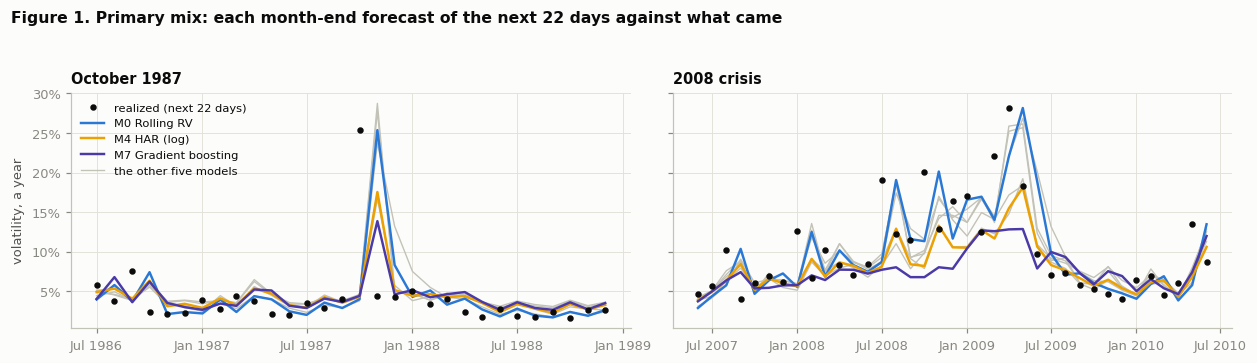

In [6]:
def annual_vol(var22):
    """A 22-day variance as an annualized volatility."""
    return np.sqrt(var22 * 252 / 22)

rs, y = RUNS["paper"], TARGETS["paper"]
windows = [("1986-07", "1988-12", "October 1987"), ("2007-06", "2010-06", "2008 crisis")]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3), sharey=True)
for ax, (lo, hi, title) in zip(axes, windows):
    span = rs["M0"].loc[lo:hi].index
    t = span.to_timestamp()
    for m in md.ORDER:
        if m not in ("M0", "M4", "M7"):
            ax.plot(t, annual_vol(rs[m].loc[span, "forecast"]), color=AXIS, lw=0.9, zorder=1)
    ax.plot(t, annual_vol(y.loc[span]), color=INK, lw=0, marker="o", ms=3.2, label="realized (next 22 days)", zorder=4)
    for m, col in (("M0", BLUE), ("M4", AMBER), ("M7", PURPLE)):
        ax.plot(t, annual_vol(rs[m].loc[span, "forecast"]), color=col, lw=1.6, label=f"{m} {md.NAMES[m]}", zorder=3)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].set_ylabel("volatility, a year")
axes[0].plot([], [], color=AXIS, lw=0.9, label="the other five models")
axes[0].legend(loc="upper left", fontsize=7.5)
fig.suptitle("Figure 1. Primary mix: each month-end forecast of the next 22 days against what came", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))

**Reading.**

- **Every model is late at the turn.** Each one forecasts by looking back, so each under-forecasts the crash month itself: October 1987, and September–October 2008. Under-forecasting is the expensive mistake for QLIKE and for the strategy.
- **They differ after the shock:**
  - Rolling RV (M0, blue) repeats last month in full. After October 1987 it forecasts about 25% for November, which turned out calm (about 4%).
  - The GARCH models (grey) jump as high and fade over several months.
  - The HAR (amber) jumps about two thirds as far.
  - Boosting (purple) is the flattest. It forecast about 13% for the 2008 peak, half of what came.
- **In calm stretches, all eight agree closely.** Most of the differences between them come from a few turbulent months.

GARCH refits where the optimizer stopped short of its tolerance (the estimate is still at least as good as the last): M2 161 of 938, M3 101 of 938
Largest ω as a share of the mean r²: M2 0.057, M3 0.072
M6 uses VIX from 1995-02 and the event counts from 1999-02
M7's tuned settings (leaves x trees) across its yearly refits:


trees,25,50,100,200,400
leaves,,,,,
4,8,4,7,5,2
8,6,6,6,3,5
16,8,4,5,2,9


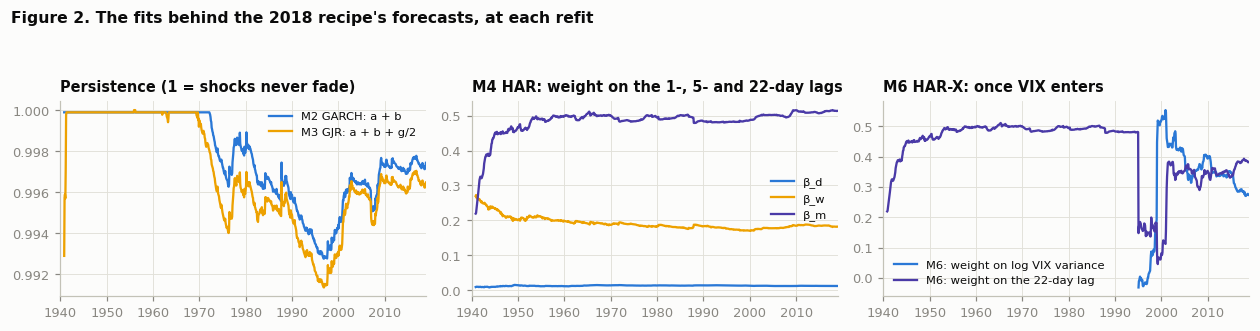

In [7]:
# What the models learned: the fits behind the last recipe's forecasts (held in 2018), refit by refit.
spec = specs["paper"]
ids = e.data.recipe_ids(spec["book"].positions)
p_last = e.data.mix(spec["book"], spec["book"].positions.iloc[-1])
x_last = md.exog(panel, p_last)
g2, g3 = md.garch_fits(p_last, False)[1], md.garch_fits(p_last, True)[1]
h4, h6 = md.har_fits(p_last, False)[1], md.har_fits(p_last, False, x_last)[1]
b7 = md.boost_fits(p_last, False, x_last)[1]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.0))
ax = axes[0]
ax.plot(g2.index.to_timestamp(), g2["a"] + g2["b"], color=BLUE, label="M2 GARCH: a + b")
ax.plot(g3.index.to_timestamp(), g3["a"] + g3["b"] + g3["g"] / 2, color=AMBER, label="M3 GJR: a + b + g/2")
ax.set_title("Persistence (1 = shocks never fade)"); ax.legend(fontsize=7.5)
ax = axes[1]
for k, col in (("d", BLUE), ("w", AMBER), ("m", PURPLE)):
    ax.plot(h4.index.to_timestamp(), h4[k], color=col, label=f"β_{k}")
ax.set_title("M4 HAR: weight on the 1-, 5- and 22-day lags"); ax.legend(fontsize=7.5)
ax = axes[2]
ax.plot(h6.index.to_timestamp(), h6["vix"], color=BLUE, label="M6: weight on log VIX variance")
ax.plot(h6.index.to_timestamp(), h6["m"], color=PURPLE, label="M6: weight on the 22-day lag")
ax.set_title("M6 HAR-X: once VIX enters"); ax.legend(fontsize=7.5)
for ax in axes:
    ax.set_xlim(pd.Timestamp("1940-01-01"), pd.Timestamp("2019-01-01"))
fig.suptitle("Figure 2. The fits behind the 2018 recipe's forecasts, at each refit", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))

print(f"GARCH refits where the optimizer stopped short of its tolerance (the estimate is still at least as good as "
      f"the last): M2 {int((~g2['converged']).sum())} of {len(g2)}, M3 {int((~g3['converged']).sum())} of {len(g3)}")
print(f"Largest ω as a share of the mean r²: M2 {(g2['omega'] / ((p_last * 100) ** 2).mean()).max():.3f}, "
      f"M3 {(g3['omega'] / ((p_last * 100) ** 2).mean()).max():.3f}")
print(f"M6 uses VIX from {h6['vix'].first_valid_index()} and the event counts from {h6['fomc'].first_valid_index()}")
print("M7's tuned settings (leaves x trees) across its yearly refits:")
display(b7.groupby(["leaves", "trees"]).size().rename("refits").unstack(fill_value=0))

**Reading.**

- **GARCH persistence sits at its 0.9999 bound from 1940 to about 1970.** The expanding window holds the 1930s, and a stationary GARCH cannot fit both that decade's level and the calm 1950s–60s, so it becomes integrated: a shock never fades. Since the 1970s, persistence has been 0.992–0.998 a day, so a shock halves in about 100–170 trading days.
- **The fixed GARCH stays well behaved.** Its largest ω is 6–7% of the mean squared return. About 11–17% of refits stop short of the optimizer's tolerance; they sit at last month's optimum and never at a worse likelihood than it (Entry 5).
- **HAR puts most of its weight on the monthly lag** (about 0.5), with about 0.2 on the weekly lag and almost none on the single day. These weights have barely moved since 1950: memory is long, and it is stable.
- **HAR-X's weights jump while the VIX sample is short.** When VIX enters in 1995, its fit uses only 1990 onward. VIX first gets almost no weight, and the monthly lag's weight drops from about 0.5 to about 0.15. When the event counts enter in 1999 and the fit starts in 1994, VIX's weight jumps to about 0.5. It then drifts down to about 0.3, while the monthly lag's weight settles near 0.35. VIX takes over part of the monthly lag's job.
- **Boosting's tuning never settles.** Across its 78 yearly refits, it picks every cell of the grid at least twice, and no setting more than 9 times. That is what an inner walk-forward shows when the nonlinear signal is weak.

## 5. Scorecard A: forecast accuracy, primary book

Mean QLIKE over the 816 holding months whose 22-day target lies inside the development sample. RV / forecast is mean realized over mean forecast: 1 is unbiased on average. MCS p is the Model Confidence Set p-value; the 90% set keeps the models with p ≥ 0.10.

In [8]:
PLACEBO = pd.read_parquet(build.PLACEBO)          # the 1,000 shuffled alphas of each model (from the build)

def scorecards(name):
    rs = RUNS[name]
    a = sc.scorecard_a(rs, TARGETS[name])
    b = sc.scorecard_b(rs)
    shuffled = PLACEBO.query("book == @name").groupby("model")["alpha_shuffled"]
    b["placebo_share"] = [float((shuffled.get_group(m) < b.loc[m, "alpha"]).mean()) for m in b.index]
    b["placebo_pass"] = b["placebo_share"] >= e.ENGINE_RULES["placebo_share"]
    return a, b, sc.select(a, rs)

def fmt_a(a):
    out = a[["qlike", "qlike_median", "rv_over_forecast", "mcs_p", "in_mcs", "qlike_rank"]].copy()
    out.index = [f"{m} {md.NAMES[m]}" for m in out.index]
    return out.style.format({"qlike": "{:.4f}", "qlike_median": "{:.4f}", "rv_over_forecast": "{:.3f}", "mcs_p": "{:.3f}"})

def fmt_b(b, name):
    cols = ["sharpe", "cer", "volatility", "mean", "gain", "reading", "alpha", "t_alpha", "mean_size", "share_capped",
            "turnover_a_year", "break_even_kappa", "placebo_share", "sharpe_rank"]
    out = b[cols].copy()
    bh = sc.buy_and_hold(RUNS[name]["M0"])
    orc = ORACLE[name]
    extra = pd.DataFrame({"buy-and-hold": bh,
                          "oracle (looks ahead)": {"sharpe": ev.sharpe(orc["excess"]), "cer": ev.cer(orc["excess"], sc.SCORE_RULES["gamma"]),
                                                   "volatility": orc["excess"].std() * np.sqrt(12), "mean": orc["excess"].mean() * 12,
                                                   "gain": ev.sharpe(orc["excess"]) - ev.sharpe(orc["bench_excess"]),
                                                   "mean_size": orc["size"].mean(), "share_capped": orc["capped"].mean(),
                                                   "turnover_a_year": orc["turnover"].iloc[1:].mean() * 12}}).T
    out.index = [f"{m} {md.NAMES[m]}" for m in out.index]
    out = pd.concat([out, extra[[c for c in cols if c in extra]]])
    return out.style.format({"sharpe": "{:.3f}", "cer": "{:.2%}", "volatility": "{:.2%}", "mean": "{:.2%}", "gain": "{:+.3f}",
                             "alpha": "{:+.2%}", "t_alpha": "{:.2f}", "mean_size": "{:.2f}", "share_capped": "{:.0%}",
                             "turnover_a_year": "{:.2f}", "break_even_kappa": "{:.2%}", "placebo_share": "{:.1%}",
                             "sharpe_rank": "{:.0f}"}, na_rep="")

def fmt_sel(sel):
    out = sel.copy()
    out.index = [f"{m} {md.NAMES[m]}" for m in out.index]
    return out.style.format({"sharpe": "{:.3f}", "gap_to_best": "{:.3f}", "gap_se": "{:.3f}"}).apply(
        lambda r: ["font-weight: bold"] * len(r) if r["chosen"] else [""] * len(r), axis=1)

TABLES = {name: scorecards(name) for name in specs}

In [9]:
a, b, sel = TABLES["paper"]
print(f"Scorecard A, primary: {int(a['months'].iloc[0])} months; Model Confidence Set at {sc.SCORE_RULES['mcs_level']:.0%} "
      f"(stationary bootstrap, mean block {sc.SCORE_RULES['mcs_block']} months, {sc.SCORE_RULES['mcs_reps']:,} draws)")
display(fmt_a(a))

Scorecard A, primary: 816 months; Model Confidence Set at 10% (stationary bootstrap, mean block 12 months, 10,000 draws)


,qlike,qlike_median,rv_over_forecast,mcs_p,in_mcs,qlike_rank
M0 Rolling RV,0.3914,0.1280,1.005,0.001,False,8
M1 EWMA,0.3441,0.1149,1.014,0.394,True,7
"M2 GARCH(1,1)",0.3237,0.1401,0.851,0.394,True,4
M3 GJR-GARCH,0.3351,0.1553,0.834,0.394,True,6
M4 HAR (log),0.3088,0.1227,1.040,0.394,True,3
M5 Downside HAR,0.3039,0.1232,1.041,0.874,True,2
M6 HAR-X,0.3025,0.1189,1.040,1.000,True,1
M7 Gradient boosting,0.3274,0.1301,1.088,0.394,True,5


**Reading.**

- **The HAR family is the most accurate.** HAR-X (M6) scores 0.3025, the downside HAR (M5) 0.3039 and the HAR (M4) 0.3088. VIX and the down-day shares add little over the plain HAR, as the hints said.
- **Rolling RV is the least accurate, by a wide margin.** It scores 0.3914 and is the only model outside the MCS (p 0.001). The other seven cannot be told apart statistically (MCS p ≥ 0.39). Even a fixed EWMA, which needs no fitting, beats rolling RV clearly.
- **The GARCH forecasts run about 15% high on average.** RV / forecast is 0.85 for M2 and 0.83 for M3. The expanding window keeps the 1930s in their long-run level. QLIKE punishes over-forecasting gently, so they still sit mid-table.
- **The mean and the median rank the models differently.** EWMA has the lowest median. The mean is driven by a few months in which a calm forecast meets a storm, and those are the months that matter for a strategy that sizes up after calm.

## 6. Scorecard B: strategy value, primary book

The same 817 holding months for every model (December 1950 to December 2018). Buy-and-hold and the oracle are reference rows, not candidates. Placebo is the share of 1,000 shuffled-forecast alphas the real alpha beats; it passes at 95%.

In [10]:
print(f"Scorecard B, primary: {int(b['months'].iloc[0])} holding months, inverse-variance timing, cap 1.5, "
      f"costs of the paper track (none); CER with γ = {sc.SCORE_RULES['gamma']}")
display(fmt_b(b, "paper"))
gap = ev.sharpe(ORACLE["paper"]["excess"]) - b.loc["M0", "sharpe"]
spread = b["sharpe"].max() - b["sharpe"].min()
print(f"Oracle minus M0: {gap:+.3f} Sharpe a year; best minus worst of the eight: {spread:.3f}")

Scorecard B, primary: 817 holding months, inverse-variance timing, cap 1.5, costs of the paper track (none); CER with γ = 5


,sharpe,cer,volatility,mean,gain,reading,alpha,t_alpha,mean_size,share_capped,turnover_a_year,break_even_kappa,placebo_share,sharpe_rank
M0 Rolling RV,1.517,5.82%,4.12%,6.24%,+0.306,edge,+2.66%,6.30,0.67,11%,3.30,0.41%,100.0%,6
M1 EWMA,1.525,6.39%,4.53%,6.90%,+0.313,edge,+2.78%,5.90,0.74,15%,2.49,0.61%,100.0%,5
"M2 GARCH(1,1)",1.551,8.42%,6.01%,9.32%,+0.340,edge,+3.28%,5.42,1.00,24%,3.53,0.60%,100.0%,3
M3 GJR-GARCH,1.567,8.68%,6.14%,9.62%,+0.355,edge,+3.39%,5.61,1.02,25%,3.56,0.64%,100.0%,1
M4 HAR (log),1.538,7.54%,5.37%,8.27%,+0.327,edge,+2.84%,5.65,0.89,17%,3.15,0.59%,100.0%,4
M5 Downside HAR,1.509,7.28%,5.29%,7.98%,+0.297,edge,+2.67%,5.06,0.87,17%,3.12,0.54%,100.0%,8
M6 HAR-X,1.552,7.64%,5.39%,8.36%,+0.341,edge,+2.87%,5.96,0.90,17%,2.94,0.66%,100.0%,2
M7 Gradient boosting,1.510,7.07%,5.12%,7.73%,+0.299,edge,+2.61%,5.44,0.83,15%,3.22,0.50%,100.0%,7
buy-and-hold,1.211,7.40%,7.17%,8.69%,,,,,1.00,,0.25,,,
oracle (looks ahead),2.222,9.05%,4.28%,9.51%,+1.011,,,,0.89,26%,3.85,,,


Oracle minus M0: +0.705 Sharpe a year; best minus worst of the eight: 0.058


**Reading.**

- **All eight beat buy-and-hold by a wide margin.**
  - Their Sharpe ratios run from 1.51 to 1.57, against 1.21.
  - Every gain reads **"edge"** on the primary test (p ≤ 0.004), α is 2.6–3.4% a year (t 5–6), and every real forecast beats all 1,000 of its shuffled versions.
  - These are development-sample numbers on a book that holds untradeable BAB, before costs, with Phase 4's full-sample asset list. They are an upper bound and not the final test, which is the holdout's.
- **The eight differ by only 0.058 Sharpe.** The GARCH family is on top: M3 1.567, HAR-X 1.552, M2 1.551. The downside HAR and boosting are at the bottom (1.509 and 1.510).
- **The oracle reaches 2.22, 0.71 above rolling RV.** Knowing next month's variance would be worth far more than anything these models capture. The forecasts take at most 0.05 of that room.
- **Size, volatility and CER.**
  - The GARCH runs hold about 1.0 on average and are capped in a quarter of months. Rolling RV holds 0.67 and is capped in 11%. So their volatilities differ (6.0–6.1% against 4.1%), all below buy-and-hold's 7.2%.
  - The CER (γ = 5) follows the size: 8.4–8.7% for the GARCH runs, above buy-and-hold's 7.4%. Rolling RV (5.8%) and EWMA (6.4%) fall below buy-and-hold despite their higher Sharpe ratios. This is the size gap a CER can hide (Entry 3), and why volatility is shown beside it.
- **Costs.** The break-even cost of timing is 0.41–0.66% one-way, on 2.5–3.6 times the account traded a year. The costs inside each factor come on top.

## 7. The two scorecards together (Q4)

Each dot is one model, on the same months. If accuracy drove strategy value, the dots would fall from top left to bottom right.

Primary (market + momentum + BAB): rank correlation of the Sharpe ranking with the QLIKE ranking +0.10, with the mean size +0.76
SPY reference (market factor): rank correlation of the Sharpe ranking with the QLIKE ranking +0.62, with the mean size +0.55


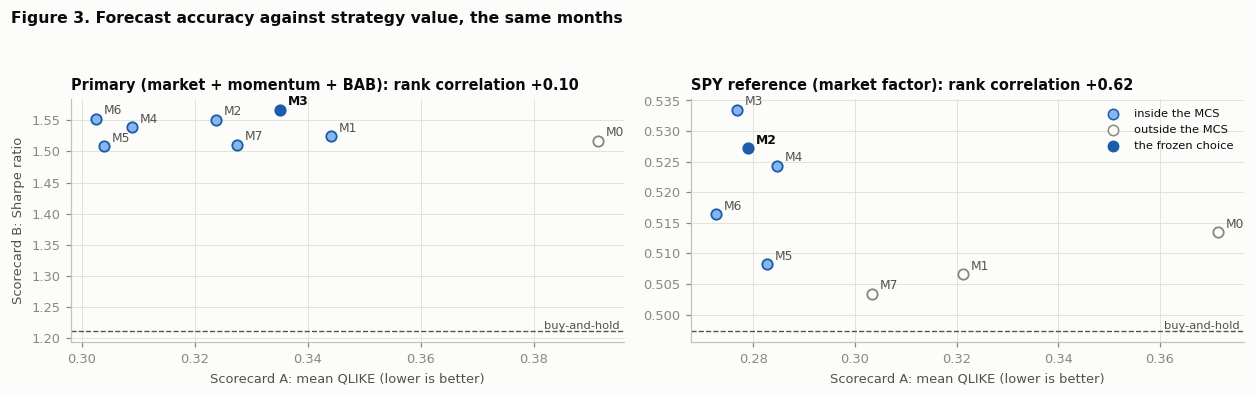

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
for ax, name in zip(axes, specs):
    a, b, sel = TABLES[name]
    chosen = sel.index[sel["chosen"]][0]
    for m in md.ORDER:
        x, y = a.loc[m, "qlike"], b.loc[m, "sharpe"]
        inside = a.loc[m, "in_mcs"]
        ax.scatter(x, y, s=46, color=DARK if m == chosen else (LIGHT if inside else SURFACE),
                   edgecolor=DARK if inside or m == chosen else MUTED, linewidth=1.2, zorder=3)
        ax.annotate(m, (x, y), xytext=(5, 3), textcoords="offset points", fontsize=8,
                    color=INK if m == chosen else INK2, fontweight="bold" if m == chosen else "normal")
    ax.axhline(sc.buy_and_hold(RUNS[name]["M0"])["sharpe"], color=INK2, lw=0.9, ls="--")
    ax.text(ax.get_xlim()[1], sc.buy_and_hold(RUNS[name]["M0"])["sharpe"], "buy-and-hold ", ha="right", va="bottom", fontsize=7.5, color=INK2)
    rho = sc.rank_agreement(a, b)
    ax.set_title(f"{BOOK_NAMES[name]}: rank correlation {rho:+.2f}")
    ax.set_xlabel("Scorecard A: mean QLIKE (lower is better)")
axes[0].set_ylabel("Scorecard B: Sharpe ratio")
handles = [plt.scatter([], [], s=46, color=LIGHT, edgecolor=DARK, label="inside the MCS"),
           plt.scatter([], [], s=46, color=SURFACE, edgecolor=MUTED, label="outside the MCS"),
           plt.scatter([], [], s=46, color=DARK, edgecolor=DARK, label="the frozen choice")]
axes[1].legend(handles=handles, loc="upper right", fontsize=7.5)
fig.suptitle("Figure 3. Forecast accuracy against strategy value, the same months", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
for name in specs:
    a, b, _ = TABLES[name]
    print(f"{BOOK_NAMES[name]}: rank correlation of the Sharpe ranking with the QLIKE ranking {sc.rank_agreement(a, b):+.2f}, "
          f"with the mean size {b['sharpe'].astype(float).corr(b['mean_size'].astype(float), method='spearman'):+.2f}")

**Reading.**

- **Primary book: rank correlation +0.10.** The most accurate forecasts (HAR-X, the downside HAR) are not the best strategies. The GARCH models, mid-table on QLIKE, are the best on Sharpe. On this book, **forecast accuracy is not the bottleneck.**
- **Market: +0.62.** Here accuracy and value agree more. Rolling RV, EWMA and boosting are near the bottom on both.
- **What the primary book's Sharpe ranking follows instead: the average size** (rank correlation +0.76). On the market, size (+0.55) and accuracy (+0.62) both track it.
  - The size is $c_t \times 1/\hat\sigma^2_t$, with $c_t$ matched in real time to buy-and-hold's past volatility.
  - A jumpy forecast, like rolling RV, gives $1/\hat\sigma^2$ a long right tail after calm months. So the matched $c_t$ is small and the typical size low.
  - A smooth forecast lets $c_t$ be larger. The 1.5 cap then binds in a quarter of months, and on this book, as in Phases 4 and 5, the cap raises the Sharpe ratio.
  - What helps the strategy here is a forecast that moves less, more than one that scores better. With eight models this is a pattern, not a test.

## 8. The selection rule: the combined portfolio

The simplest model (in the order M0 to M7) that is inside the MCS **and** whose Sharpe ratio is within one standard error of the best. The standard error is that of the gap to the best, by the primary test's method.

In [12]:
display(fmt_sel(TABLES["paper"][2]))
sel = TABLES["paper"][2]
print(f"Best Sharpe: {sel.index[sel['best']][0]}. Frozen choice for the combined portfolio: {sel.index[sel['chosen']][0]}"
      f"{' (fallback: no MCS member within one error)' if sel['fallback'].iloc[0] else ''}")

,sharpe,gap_to_best,gap_se,within_1se,in_mcs,best,fallback,chosen
M0 Rolling RV,1.517,0.049,0.057,True,False,False,False,False
M1 EWMA,1.525,0.042,0.040,False,True,False,False,False
"M2 GARCH(1,1)",1.551,0.015,0.010,False,True,False,False,False
M3 GJR-GARCH,1.567,0.000,0.000,True,True,True,False,True
M4 HAR (log),1.538,0.028,0.022,False,True,False,False,False
M5 Downside HAR,1.509,0.058,0.033,False,True,False,False,False
M6 HAR-X,1.552,0.014,0.025,True,True,False,False,False
M7 Gradient boosting,1.510,0.056,0.038,False,True,False,False,False


Best Sharpe: M3. Frozen choice for the combined portfolio: M3


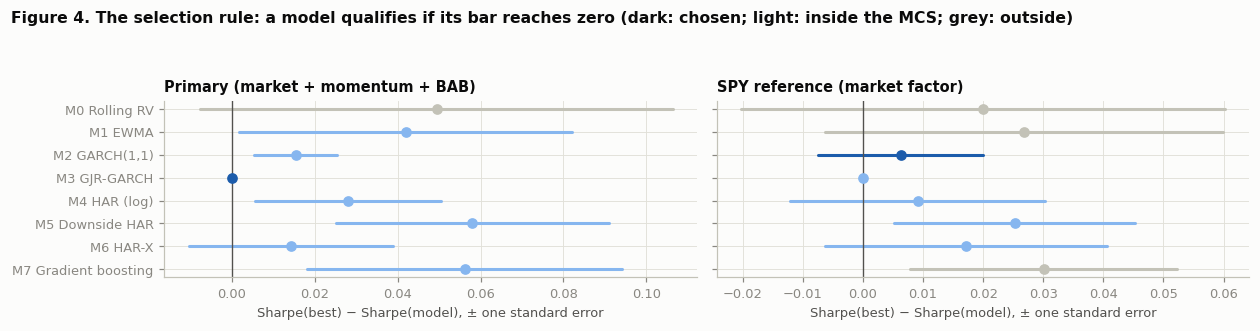

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.0), sharey=True)
for ax, name in zip(axes, specs):
    sel = TABLES[name][2]
    yy = np.arange(len(md.ORDER))[::-1]
    for y0, m in zip(yy, md.ORDER):
        r = sel.loc[m]
        col = DARK if r["chosen"] else (LIGHT if r["in_mcs"] else AXIS)
        ax.plot([r["gap_to_best"] - r["gap_se"], r["gap_to_best"] + r["gap_se"]], [y0, y0], color=col, lw=2.0, solid_capstyle="round")
        ax.plot(r["gap_to_best"], y0, "o", color=col, ms=6, zorder=3)
    ax.axvline(0, color=INK2, lw=0.9)
    ax.set_yticks(yy, [f"{m} {md.NAMES[m]}" for m in md.ORDER])
    ax.set_xlabel("Sharpe(best) − Sharpe(model), ± one standard error")
    ax.set_title(BOOK_NAMES[name])
fig.suptitle("Figure 4. The selection rule: a model qualifies if its bar reaches zero (dark: chosen; light: inside the MCS; grey: outside)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))

**Result: M3, GJR-GARCH, frozen for the combined portfolio.**

- **The best Sharpe ratio is M3's** (1.567). Every model except rolling RV is inside the MCS.
- **Within one standard error of M3:** rolling RV (outside the MCS) and HAR-X, but not:
  - **EWMA**, which misses by 0.002 (a gap of 0.042 against an error of 0.040);
  - **GARCH(1,1)**, which misses by 0.005 (0.015 against 0.010). The two GARCH models move together, so the error of their gap is small.
- So the simplest qualifying model is M3 itself. The fallback was not needed.
- **A knife-edge choice.** Had EWMA's error been 0.002 larger, the rule would have picked EWMA. The rule was fixed in advance, so the choice stands. The margin is recorded in Entry 5 and will be reported beside every result that uses M3.
- **Against the hints.** Test 3 found no asymmetry in $p_t$, yet GJR has the best Sharpe ratio. Its lead over plain GARCH (0.015, 1.5 standard errors) does not come from an asymmetry the hints could see. It may be luck, and the holdout will test it.

## 9. The SPY reference (market factor)

The same scorecards and rule on the market factor timed alone, traded at SPY's costs: 870 holding months, July 1946 to December 2018.

In [14]:
a, b, sel = TABLES["spy"]
print(f"Scorecard A, SPY reference (market factor): {int(a['months'].iloc[0])} months")
display(fmt_a(a))
print(f"Scorecard B, SPY reference: {int(b['months'].iloc[0])} holding months, SPY's costs (5 bp a trade, borrowing at rf + 0.5%)")
display(fmt_b(b, "spy"))
display(fmt_sel(sel))
print(f"Best Sharpe: {sel.index[sel['best']][0]}. Frozen choice for the SPY reference: {sel.index[sel['chosen']][0]}"
      f"{' (fallback: no MCS member within one error)' if sel['fallback'].iloc[0] else ''}")

Scorecard A, SPY reference (market factor): 869 months


,qlike,qlike_median,rv_over_forecast,mcs_p,in_mcs,qlike_rank
M0 Rolling RV,0.3715,0.1083,1.014,0.000,False,8
M1 EWMA,0.3212,0.0827,1.017,0.008,False,7
"M2 GARCH(1,1)",0.2790,0.1151,0.923,0.580,True,3
M3 GJR-GARCH,0.2768,0.1077,0.932,0.683,True,2
M4 HAR (log),0.2846,0.1079,0.976,0.456,True,5
M5 Downside HAR,0.2828,0.1055,0.992,0.580,True,4
M6 HAR-X,0.2727,0.0958,0.987,1.000,True,1
M7 Gradient boosting,0.3035,0.1265,0.958,0.008,False,6


Scorecard B, SPY reference: 870 holding months, SPY's costs (5 bp a trade, borrowing at rf + 0.5%)


,sharpe,cer,volatility,mean,gain,reading,alpha,t_alpha,mean_size,share_capped,turnover_a_year,break_even_kappa,placebo_share,sharpe_rank
M0 Rolling RV,0.513,2.62%,11.02%,5.66%,+0.016,inconclusive,+1.30%,1.59,0.82,19%,3.56,0.10%,97.4%,5
M1 EWMA,0.507,2.52%,11.53%,5.84%,+0.009,inconclusive,+1.17%,1.44,0.86,20%,2.68,0.09%,96.1%,7
"M2 GARCH(1,1)",0.527,2.45%,14.16%,7.46%,+0.030,inconclusive,+1.28%,1.52,1.07,29%,3.02,0.19%,98.1%,2
M3 GJR-GARCH,0.533,2.48%,14.51%,7.74%,+0.036,inconclusive,+1.38%,1.61,1.10,32%,3.19,0.21%,98.9%,1
M4 HAR (log),0.524,2.61%,12.83%,6.73%,+0.027,inconclusive,+1.20%,1.52,0.97,23%,3.27,0.16%,97.4%,3
M5 Downside HAR,0.508,2.40%,12.88%,6.55%,+0.011,inconclusive,+1.02%,1.26,0.97,23%,3.28,0.09%,95.4%,6
M6 HAR-X,0.516,2.50%,12.92%,6.67%,+0.019,inconclusive,+1.10%,1.39,0.98,26%,2.99,0.13%,96.6%,4
M7 Gradient boosting,0.503,2.27%,13.31%,6.70%,+0.006,inconclusive,+0.94%,1.15,1.00,22%,3.07,0.08%,94.5%,8
buy-and-hold,0.497,1.91%,14.69%,7.31%,,,,,1.00,,0.00,,,
oracle (looks ahead),1.124,9.50%,11.29%,12.69%,+0.627,,,,0.95,30%,3.38,,,


,sharpe,gap_to_best,gap_se,within_1se,in_mcs,best,fallback,chosen
M0 Rolling RV,0.513,0.020,0.040,True,False,False,False,False
M1 EWMA,0.507,0.027,0.033,True,False,False,False,False
"M2 GARCH(1,1)",0.527,0.006,0.014,True,True,False,False,True
M3 GJR-GARCH,0.533,0.000,0.000,True,True,True,False,False
M4 HAR (log),0.524,0.009,0.021,True,True,False,False,False
M5 Downside HAR,0.508,0.025,0.020,False,True,False,False,False
M6 HAR-X,0.516,0.017,0.023,True,True,False,False,False
M7 Gradient boosting,0.503,0.030,0.022,False,False,False,False,False


Best Sharpe: M3. Frozen choice for the SPY reference: M2


**Result: M2, GARCH(1,1), frozen for the SPY reference.**

- **Accuracy.** HAR-X is the most accurate (0.2727), then GJR and GARCH. Rolling RV, EWMA and boosting are outside the MCS. The curvature hint did not help boosting: it is dropped.
- **Value.** The gains over buy-and-hold (0.497) are small, 0.006–0.036 Sharpe, and every reading is "inconclusive". This matches what Cederburg et al. find for the market (Entry 1).
  - At SPY's costs, the break-even κ is 0.08–0.21% one-way, against the 0.05% assumed. The margin is thin.
  - Seven of eight models pass the placebo; boosting fails at 94.5%.
  - The oracle (1.12) shows the room is large here too.
- **Selection.** The best Sharpe ratio is GJR's (0.533). GARCH(1,1) is the simplest model inside the MCS within one standard error of it (a gap of 0.006 against an error of 0.014). Rolling RV and EWMA are within one error but outside the MCS.

## 10. The VIX era (information only)

From March 1995, the first month M6 uses VIX, to December 2018: 286 months. These are the same runs read on those months only; $c_t$ is not re-estimated. Nothing here changes a choice.

In [15]:
# Information only: the months in which M6 uses VIX (from its first refit with 60 months of VIX).
rows = {}
for name in specs:
    rs, y = RUNS[name], TARGETS[name]
    p_any = e.data.mix(specs[name]["book"], specs[name]["book"].positions.iloc[-1])
    start = md.har_fits(p_any, False, md.exog(panel, p_any))[1]["vix"].first_valid_index() + 1
    sub = {m: r.loc[start:] for m, r in rs.items()}
    a = sc.scorecard_a(sub, y)
    for m in md.ORDER:
        rows[(BOOK_NAMES[name], f"{m} {md.NAMES[m]}")] = {"from": str(start), "qlike": a.loc[m, "qlike"], "in_mcs": a.loc[m, "in_mcs"],
                                                         "sharpe": ev.sharpe(sub[m]["excess"]),
                                                         "buy-and-hold sharpe": ev.sharpe(sub[m]["bench_excess"])}
vix = pd.DataFrame(rows).T
display(vix.style.format({"qlike": "{:.4f}", "sharpe": "{:.3f}", "buy-and-hold sharpe": "{:.3f}"}))

**Reading.**

- **VIX helps the market forecast.** On the market, HAR-X is clearly the most accurate in the VIX era (0.230, against 0.250 for the next best), as Test 5 said. On the primary book, the downside HAR and HAR-X lead (0.252), with the GARCH models close.
- **No Sharpe ranking carries over.** The best strategy in this window is EWMA on the primary book (1.68) and rolling RV on the market (0.74). Over 24 years these differences are noise, which is why the choice is made on the full development sample.
- **Timing beats buy-and-hold in this window for every model on both books.** Buy-and-hold's Sharpe ratio is 0.95 on the primary book and 0.52 on the market.

## 11. The first run and the GARCH fix (PREREGISTRATION Entry 5)

**What happened.** In the first run, the GARCH optimizer (SLSQP) sometimes reported success at a point far worse than where it started. ω came out about 10⁹ times too large, and each refit starts from the last estimate, so the bad point was carried forward month after month. On the primary book, 1,195 of 73,164 GJR refits were degenerate. Some GJR forecasts reached 5.7 × 10¹⁰ times rolling RV's, and GJR's mean QLIKE was 0.957. The market's fits were clean.

**The fix.** ω is now optimized as a share of the mean squared return (so all parameters are of similar scale) and capped there. A refit is kept only if its likelihood beats its start's. On real data the estimates match the `arch` package to four decimals. The build now stops if any forecast strays more than 1,000 times from rolling RV's. Nothing else changed.

**Why the first run's choice is void.** It chose rolling RV for the combined portfolio. Rolling RV was inside the MCS only because its p-value (0.117) came from the round that removed the broken GJR, whose wild losses made that round's test too noisy to reject. The table shows both runs side by side.

In [16]:
# The first run (before the GARCH fix of Entry 5), kept as a record, beside this run.
first_a = pd.read_csv(ROOT / "reports" / "phase6_first_run_scorecard_a.csv", index_col=[0, 1])
first_s = pd.read_csv(ROOT / "reports" / "phase6_first_run_selection.csv", index_col=[0, 1])
rows = {}
for name in specs:
    a, b, sel = TABLES[name]
    for m in md.ORDER:
        rows[(BOOK_NAMES[name], f"{m} {md.NAMES[m]}")] = {
            "first run: QLIKE": first_a.loc[(name, m), "qlike"], "QLIKE": a.loc[m, "qlike"],
            "first run: MCS p": first_a.loc[(name, m), "mcs_p"], "MCS p": a.loc[m, "mcs_p"],
            "first run: Sharpe": first_s.loc[(name, m), "sharpe"], "Sharpe": sel.loc[m, "sharpe"],
            "first run: chosen": bool(first_s.loc[(name, m), "chosen"]), "chosen": bool(sel.loc[m, "chosen"])}
display(pd.DataFrame(rows).T.style.format({c: "{:.4f}" for c in ["first run: QLIKE", "QLIKE"]}
                                           | {c: "{:.3f}" for c in ["first run: MCS p", "MCS p", "first run: Sharpe", "Sharpe"]}))

**Reading.** Only GARCH(1,1) and GJR-GARCH change, and on the market they change only in the fourth decimal.

On the primary book, GJR's mean QLIKE falls from 0.957 to 0.335 and its Sharpe ratio rises from 1.519 to 1.567. Rolling RV's MCS p-value falls from 0.117 to 0.001, so it leaves the set. The choice moves from rolling RV to GJR-GARCH.

The fix was made after the first run's choice had been seen. It was made because no reading of the plan allows a forecast of 10¹⁰ times the realized variance, and the re-run decides. Entry 5 records both runs.

## 12. Frozen choices

Frozen from Phase 7 on (PREREGISTRATION Entry 5); their clean test is the holdout.

In [17]:
frozen = pd.DataFrame({BOOK_NAMES[n]: {"frozen model": TABLES[n][2].index[TABLES[n][2]["chosen"]][0],
                                        "name": md.NAMES[TABLES[n][2].index[TABLES[n][2]["chosen"]][0]],
                                        "best Sharpe of the eight": TABLES[n][2].index[TABLES[n][2]["best"]][0],
                                        "fallback used": bool(TABLES[n][2]["fallback"].iloc[0]),
                                        "rank correlation (Q4)": round(sc.rank_agreement(TABLES[n][0], TABLES[n][1]), 2)}
                       for n in specs}).T
display(frozen)

,frozen model,name,best Sharpe of the eight,fallback used,rank correlation (Q4)
Primary (market + momentum + BAB),M3,GJR-GARCH,M3,False,0.1000
SPY reference (market factor),M2,"GARCH(1,1)",M3,False,0.6200


| Choice | Model | Margin |
|---|---|---|
| Combined portfolio | **M3 GJR-GARCH**: zero-mean Gaussian QMLE on the daily returns of the mix held next month, expanding window, refit every month-end with Entry 5's safeguards; the 22-day forecast sums h-step forecasts decaying at a + b + g/2 | best Sharpe; EWMA missed the one-standard-error rule by 0.002 |
| SPY reference | **M2 GARCH(1,1)**: the same with g = 0, applied to SPY alone | simplest model inside the MCS within one standard error of the best |

## Using the models

```python
from src import engine as e
from src import models as md
from src.models import build, scorecard as sc
from src.data.load import load_dev

panel = load_dev()
specs = build.setup(panel)                       # "paper" (primary) and "spy" (market factor): book, costs, forecasters
f = specs["paper"]["fs"]["M3"]                   # the frozen forecaster for the combined portfolio
res = sc.run(specs["paper"]["book"], f, specs["paper"]["costs"])   # the engine at the primary specification
e.evaluation.sharpe_gain_test(res)              # the primary test

md.garch_fits(p, gjr=True)                       # forecasts and every refit's parameters for a mix p
md.har_fits(p, down=False, x=md.exog(panel, p))  # M6: forecasts and coefficients (build M6/M7 inputs only with md.exog)
```

```bash
python -m src.models.build           # fill the forecast cache in parallel, run the placebos, write reports/phase6_*.csv
```